# Hotel Harmony – EDA Project

# Our business objective:

Elite Hotels International wants to:
1. Reduce booking cancellations.
2. Improve hotel occupancy.
3. Increase revenue.
4. Understand customer behaviour.
5. Improve guest satisfaction.

# Our analytical roadmap

| Phase | Work |
|---|---|
| 1 | Dataset understanding |
| 2 | Data inspection |
| 3 | Data cleaning |
| 4 | Univariate analysis |
| 5 | Bivariate & multivariate analysis |
| 6 | Business insights & visualizations |
| 7 | Advanced statistical analysis |
| 8 | Final business recommendations |

# Phase 1: Dataset Understanding

Step 1.1 – Import Libraries

In [1]:
# Importing essential libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Step 1.2 – Load the Dataset

In [2]:
# Loading the hotel booking dataset
df = pd.read_csv('hotel_bookings.csv')

Step 1.3 – Check Dataset Shape

In [5]:
# Checking rows and columns
print("Dataset Shape:", df.shape)
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Dataset Shape: (119390, 32)
Total Rows: 119390
Total Columns: 32


Step 1.4 – Display First 5 Records

In [6]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


Step 1.5 – Display Last 5 Records

In [7]:
df.tail()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,...,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,2017-09-07


Step 1.6 – Check Column Names

In [8]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='str')

Step 1.7 – Check Data Types and Non-Null Counts

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

# Step 2: Initial Data Inspection

Objective: Understand the dataset's quality before making any changes.

Step 2.1 – Missing Values

In [10]:
# Checking missing values in each column
missing = df.isnull().sum()

# Displaying only columns containing missing values
print(missing[missing > 0])


children         4
country        488
agent        16340
company     112593
dtype: int64


Step 2.2 – Duplicate Records

In [11]:
# Checking total duplicate rows

print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 31994


Step 2.3 – Numerical Summary

In [12]:
# Statistical summary of numerical columns

display(df.describe())

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [13]:
# Checking missing values
print(df.isnull().sum()[df.isnull().sum() > 0])

# Checking duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

children         4
country        488
agent        16340
company     112593
dtype: int64

Duplicate Rows: 31994


# Step 3 – Targeted Data Cleaning

Step 3.1 – Inspect missing children records

In [14]:
# Displaying records where children is missing
display(df[df['children'].isnull()])

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
40600,City Hotel,1,2,2015,August,32,3,1,0,2,...,No Deposit,NaN,NaN,0,Transient-Party,12.0,0,1,Canceled,2015-08-01
40667,City Hotel,1,1,2015,August,32,5,0,2,2,...,No Deposit,14.0,NaN,0,Transient-Party,12.0,0,1,Canceled,2015-08-04
40679,City Hotel,1,1,2015,August,32,5,0,2,3,...,No Deposit,NaN,NaN,0,Transient-Party,18.0,0,2,Canceled,2015-08-04
41160,City Hotel,1,8,2015,August,33,13,2,5,2,...,No Deposit,9.0,NaN,0,Transient-Party,76.5,0,1,Canceled,2015-08-09


Step 3.2 – Inspect duplicate records

In [15]:
# Displaying a few duplicate records
display(df[df.duplicated(keep=False)].head(10))

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
21,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,No Deposit,250.0,NaN,0,Transient,84.67,0,1,Check-Out,2015-07-07
22,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,No Deposit,250.0,NaN,0,Transient,84.67,0,1,Check-Out,2015-07-07
39,Resort Hotel,0,70,2015,July,27,2,2,3,2,...,No Deposit,250.0,NaN,0,Transient,137.00,0,1,Check-Out,2015-07-07
43,Resort Hotel,0,70,2015,July,27,2,2,3,2,...,No Deposit,250.0,NaN,0,Transient,137.00,0,1,Check-Out,2015-07-07
132,Resort Hotel,1,5,2015,July,28,5,1,0,2,...,No Deposit,240.0,NaN,0,Transient,97.00,0,0,Canceled,2015-07-01
138,Resort Hotel,1,5,2015,July,28,5,1,0,2,...,No Deposit,240.0,NaN,0,Transient,97.00,0,0,Canceled,2015-07-01
198,Resort Hotel,0,0,2015,July,28,7,0,1,1,...,No Deposit,240.0,NaN,0,Transient,109.80,0,3,Check-Out,2015-07-08
200,Resort Hotel,0,0,2015,July,28,7,0,1,1,...,No Deposit,240.0,NaN,0,Transient,109.80,0,3,Check-Out,2015-07-08


In [16]:
# Inspecting the four records with missing children values
display(
    df.loc[
        df['children'].isnull(),
        ['hotel', 'adults', 'babies', 'children', 'adr',
         'total_of_special_requests']
    ]
)

,hotel,adults,babies,children,adr,total_of_special_requests
40600,City Hotel,2,0,NaN,12.0,1
40667,City Hotel,2,0,NaN,12.0,1
40679,City Hotel,3,0,NaN,18.0,2
41160,City Hotel,2,0,NaN,76.5,1


Step 3.3 – Handle Missing Values

In [17]:
# Replacing missing children values with 0
df['children'] = df['children'].fillna(0)

# Replacing missing categorical values with Unknown
df['country'] = df['country'].fillna('Unknown')

# Replacing missing agent and company identifiers with 0
df['agent'] = df['agent'].fillna(0)
df['company'] = df['company'].fillna(0)

# Verifying missing values
print("Remaining Missing Values:")
print(df.isnull().sum().sum())

Remaining Missing Values:
0


Step 3.4 – Remove Exact Duplicates

In [18]:
# Creating a backup before removing duplicates
df_original = df.copy()

# Removing exact duplicate records
df = df.drop_duplicates()

# Checking the updated dataset
print("Original Shape:", df_original.shape)
print("Cleaned Shape:", df.shape)

print("Remaining Duplicates:", df.duplicated().sum())

Original Shape: (119390, 32)
Cleaned Shape: (87396, 32)
Remaining Duplicates: 0


Step 3.5 – Verify Cleaning

In [19]:
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("Final Dataset Shape:", df.shape)

Missing Values: 0
Duplicate Rows: 0
Final Dataset Shape: (87396, 32)


# Important analytical observation
We have removed approximately 26.8% of the original records.

# One important limitation: 
Identical booking records might occasionally represent separate real bookings. Since the dataset doesn't provide a unique reservation ID, we have treated exact duplicates as redundant observations. Document this assumption in your project.

Also, remember:
- children = 0: assumed no children where the value was missing.
- agent = 0 and company = 0: placeholders for missing identifiers.
- country = 'Unknown': preserves records without country information.

# Step 4 – Exploratory Data Analysis (EDA)

# Analysis 1: Hotel Booking Distribution
# Business question: Which hotel type receives more bookings: City Hotel or Resort Hotel?

Step 4.1 – Booking Count and Percentage

In [20]:
# Counting bookings by hotel type
hotel_bookings = df['hotel'].value_counts()

print("Hotel Booking Count:")
print(hotel_bookings)

# Calculating booking percentage
hotel_percentage = (df['hotel'].value_counts(normalize = True) * 100).round(2)

print("\nHotel Booking Percentage")
print(hotel_percentage)

Hotel Booking Count:
hotel
City Hotel      53428
Resort Hotel    33968
Name: count, dtype: int64

Hotel Booking Percentage
hotel
City Hotel      61.13
Resort Hotel    38.87
Name: proportion, dtype: float64


Step 4.2 – Visualization

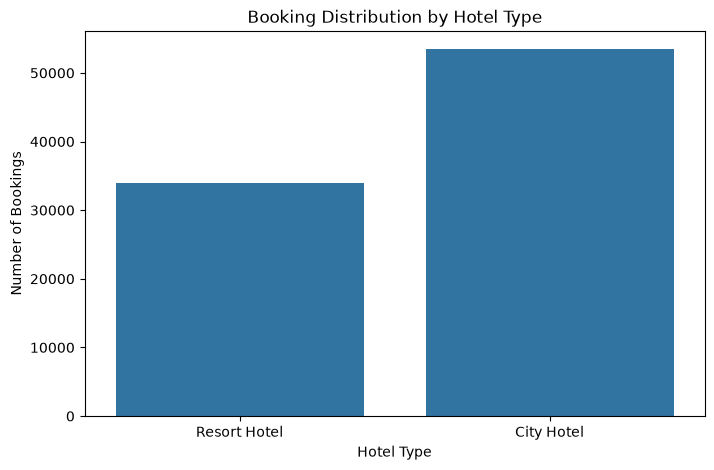

In [21]:
# Visualizing hotel booking distribution
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='hotel')

plt.title('Booking Distribution by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Number of Bookings')

plt.show()

# Interpretation
- City Hotels account for approximately 61% of all retained booking records.
- Resort Hotels account for approximately 39%.
- City Hotels have 19,460 more booking records than Resort Hotels.
# Business Insight
City Hotels demonstrate stronger booking volume, potentially reflecting demand from business travellers, urban visitors and short-stay customers.

Resort Hotels still represent a substantial share of bookings, suggesting a meaningful leisure-travel market.

# Note: 
These figures represent booking records, not necessarily completed stays or unique customers.
# Project Report Finding
You can use this in your final project documentation:
City Hotels account for 61.13% of the retained booking records, compared with 38.87% for Resort Hotels. This indicates a higher booking volume for City Hotels within the dataset. Hotel-specific marketing and pricing strategies should consider the different demand patterns of urban and resort properties.

# Analysis 2 – Booking Cancellation Analysis
Business question: What proportion of hotel bookings are cancelled, and 
how does cancellation behaviour differ between City Hotels and Resort Hotels?

In [22]:
# Counting cancelled and non-cancelled bookings
cancellation_count = df['is_canceled'].value_counts()

print("Cancellation Count:")
print(cancellation_count)

# Calculating cancellation percentage
cancellation_percentage = (
    df['is_canceled'].value_counts(normalize=True) * 100
).round(2)

print("\nCancellation Percentage:")
print(cancellation_percentage)

Cancellation Count:
is_canceled
0    63371
1    24025
Name: count, dtype: int64

Cancellation Percentage:
is_canceled
0    72.51
1    27.49
Name: proportion, dtype: float64


# Business Interpretation
Out of every 100 booking records:
- Approximately 73 bookings were not cancelled.
- Approximately 27 bookings were cancelled.
That means more than one in every four bookings was cancelled.

For hotel management, this matters because cancellations can create:
- Uncertain room demand.
- Revenue forecasting difficulties.
- Last-minute inventory management challenges.
- Potentially unused room capacity.
Important: A cancelled booking does not automatically mean lost revenue. A hotel may successfully resell that room.

# Project Report Finding
The overall booking cancellation rate was 27.49%, indicating that more than one-quarter of retained booking records were cancelled. This highlights the importance of understanding cancellation patterns and identifying the customer and booking characteristics associated with higher cancellation risk.

# Analysis 3 – Cancellation Rate by Hotel Type
Now comes a more interesting question:

Are City Hotels experiencing more cancellations than Resort Hotels?

In [26]:
# Cancellation count by hotel type
cancellation_by_hotel = pd.crosstab(
    df['hotel'],
    df['is_canceled']
)

print(cancellation_by_hotel)

# Cancellation percentage by hotel type
cancellation_rate = (
    pd.crosstab(df['hotel'], df['is_canceled'], normalize='index') * 100
).round(2)

print("\nCancellation Rate by Hotel Type:")
print(cancellation_rate)

is_canceled       0      1
hotel                     
City Hotel    37379  16049
Resort Hotel  25992   7976

Cancellation Rate by Hotel Type:
is_canceled       0      1
hotel                     
City Hotel    69.96  30.04
Resort Hotel  76.52  23.48


Notice that we're using normalize='index'.

It calculates cancellation percentages within each hotel type, rather than across the entire dataset.

# Interpretation
- City Hotels have a 30.04% cancellation rate.
- Resort Hotels have a 23.48% cancellation rate.
- The difference is 6.56 percentage points.
City Hotels experience a higher cancellation rate than Resort Hotels.

This suggests that City Hotel bookings may be more vulnerable to cancellation.

However, we should investigate other factors before identifying the reasons.

# Business Recommendations
For City Hotels:
- Monitor bookings with longer lead times.
- Review cancellation policies.
- Identify customer segments with higher cancellation rates.
- Consider targeted confirmation and reminder strategies.
# For Resort Hotels:
- Maintain existing booking retention practices.
- Investigate which customer segments contribute to their relatively lower cancellation rate.
# Project Report Finding
City Hotels recorded a cancellation rate of 30.04%, compared with 23.48% for Resort Hotels. This represents a 6.56-percentage-point difference, indicating that City Hotels face a greater booking cancellation challenge. Further investigation into lead time, deposit type and market segment may help identify the underlying factors.

# Analysis 4 – Monthly Booking Trends
Now let's investigate seasonality.

# Business question: Which months attract the highest booking volume?

This can help hotel management understand seasonal demand and plan pricing, staffing and room availability.

In [27]:
# Monthly booking distribution
monthly_bookings = (
    df['arrival_date_month']
    .value_counts()
    .reindex([
        'January', 'February', 'March', 'April',
        'May', 'June', 'July', 'August',
        'September', 'October', 'November', 'December'
    ])
)

print("Monthly Booking Count:")
print(monthly_bookings)

Monthly Booking Count:
arrival_date_month
January       4693
February      6098
March         7513
April         7908
May           8355
June          7765
July         10057
August       11257
September     6690
October       6934
November      4995
December      5131
Name: count, dtype: int64


# Monthly Booking Trend

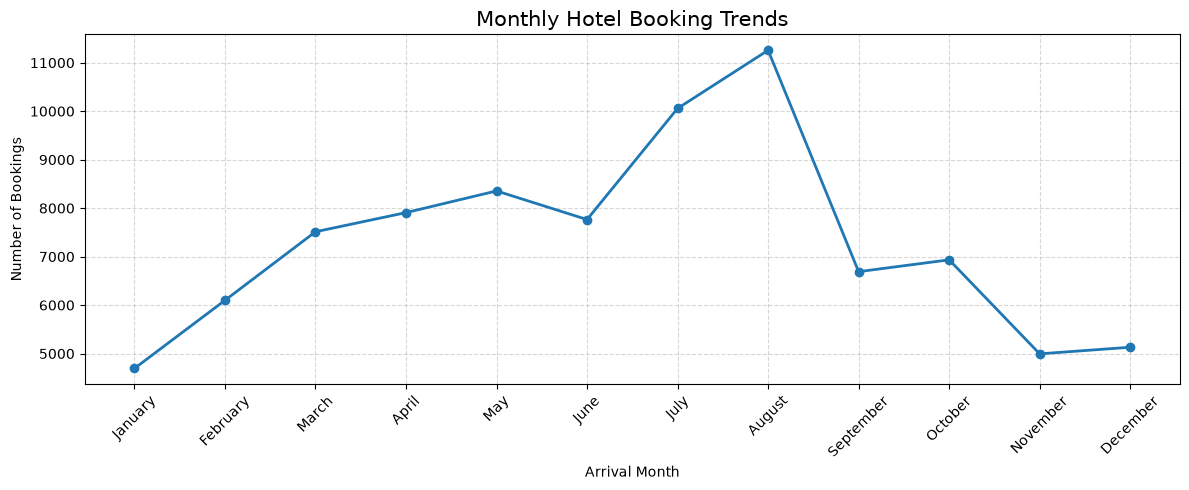

In [28]:
import matplotlib.pyplot as plt

# Monthly booking data
monthly_bookings = df['arrival_date_month'].value_counts().reindex([
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
])

# Create line chart
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_bookings.index,
    monthly_bookings.values,
    marker='o',
    linewidth=2
)

plt.title('Monthly Hotel Booking Trends', fontsize=15)
plt.xlabel('Arrival Month')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()

# What does this tell us?
1. July–August: Booking volume reaches its highest level, suggesting a strong seasonal demand period.
2. January–February: Booking volume is relatively low.
3. September: Bookings drop noticeably after the August peak.
4. Overall: Demand is not evenly distributed throughout the year; hotel operations may need to adapt to seasonal fluctuations.
# Business interpretation
Hotels could consider increasing staffing and preparing room availability during the July–August peak, while using targeted promotions during relatively quieter months.

# Important:
These are booking arrival-month patterns, not occupancy rates. We don't have the total room capacity needed to calculate occupancy.
# Portfolio-ready observation
Monthly booking analysis revealed a seasonal pattern, with August recording the highest booking volume (11,257), followed by July (10,057). January had the lowest volume (4,693). This variation suggests that hotels should align staffing, pricing strategies and operational planning with seasonal demand.

# Analysis 5 – Booking Lead Time
Let's investigate how far in advance guests typically book their hotel stays. 
This can help us understand booking behavior and cancellation risk.

In [29]:
print("Lead Time Summary:")
print(df['lead_time'].describe().round(2))

Lead Time Summary:
count    87396.00
mean        79.89
std         86.05
min          0.00
25%         11.00
50%         49.00
75%        125.00
max        737.00
Name: lead_time, dtype: float64


# Important observations
# A. Mean > Median

Average lead time is approximately 80 days, while the median is 49 days.

This suggests a right-skewed distribution: some guests book much further in advance, increasing the average.

# B. Considerable variation

The standard deviation is 86.05 days, indicating that booking lead times vary substantially.

# C. Wide booking window

The maximum lead time is 737 days, meaning some bookings were made almost two years before arrival.
# Business interpretation
Hotels should consider different booking strategies for different customer groups:
- Early bookings: monitor long-term demand and booking cancellations.
- Last-minute bookings: consider flexible pricing and room availability.
- Advance bookings: evaluate whether longer lead times are associated with higher cancellation risk.

# Portfolio-ready observation
The average booking lead time was 79.89 days, while the median was 49 days. The difference between these measures suggests a positively skewed distribution, with some guests making reservations substantially in advance. The wide standard deviation of 86.05 days further indicates considerable variation in booking behavior.

A histogram will help us see how frequently guests book at different lead-time intervals.

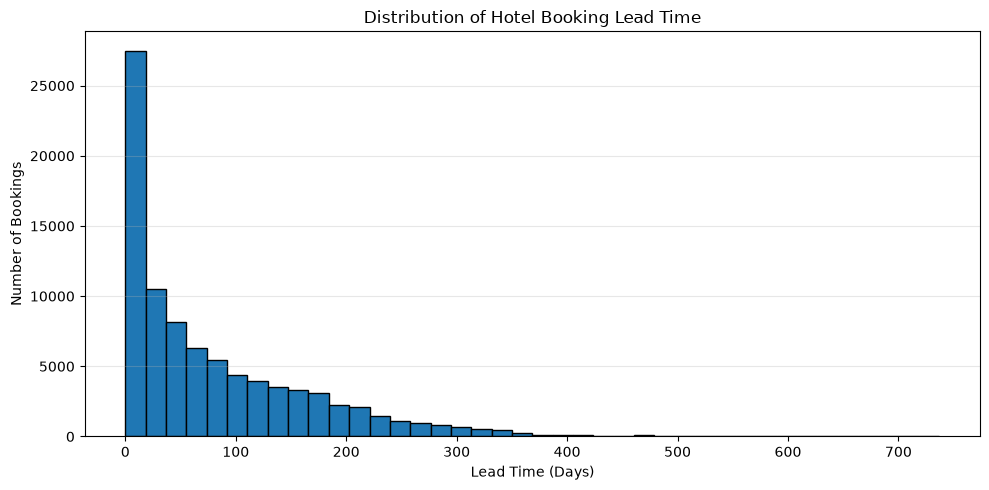

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(df['lead_time'], bins=40, edgecolor='black')

plt.title('Distribution of Hotel Booking Lead Time')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Number of Bookings')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

The lead-time distribution is highly positively (right) skewed.
# What does that mean?
- Most bookings are concentrated around shorter lead times.
- A smaller proportion of guests book many months in advance.
- Those unusually large lead-time values stretch the distribution towards the right.
- This explains why the mean (79.89 days) is higher than the median (49 days).
# Portfolio insight
The lead-time distribution exhibited substantial positive skewness, indicating that most guests booked relatively closer to their arrival dates, while a smaller segment made reservations significantly further in advance. Consequently, the mean lead time (79.89 days) exceeded the median (49 days).

# Analysis 6 – Guest Composition
Let's understand how many adults, children and babies are included in hotel bookings.

In [31]:
guest_summary = df[['adults', 'children', 'babies']].describe().round(2)

print(guest_summary)

         adults  children    babies
count  87396.00  87396.00  87396.00
mean       1.88      0.14      0.01
std        0.63      0.46      0.11
min        0.00      0.00      0.00
25%        2.00      0.00      0.00
50%        2.00      0.00      0.00
75%        2.00      0.00      0.00
max       55.00     10.00     10.00


# What do these results tell us?
# A. Adults
- The average booking includes approximately 2 adults.
- Median is also 2.
- This suggests that bookings are predominantly made for two adults.
# B. Children
- The median is 0.
- Even at the 75th percentile, the value remains 0.
- This means at least 75% of bookings have no children recorded.
# C. Babies
- The mean is just 0.01.
- The median is 0.
- Bookings involving babies are relatively uncommon.
# Data quality observation ⚠️
Look at the maximum values:
- Adults: 55
- Children: 10
- Babies: 10
These are unusual for ordinary hotel reservations.

We should investigate them rather than automatically delete them. Some records may represent group bookings or data-entry errors.
# Portfolio-ready observation
Guest composition analysis revealed that hotel bookings predominantly involved two adults, with a median of zero children and zero babies. This indicates that the dataset is largely characterized by adult-focused reservations. However, unusually high maximum values for adults (55), children (10) and babies (10) warrant further investigation.

# Analysis 7 – Total Guests per Booking

Let's combine adults, children and babies to understand the total number of guests associated with each booking.

In [32]:
df['total_guests'] = (
    df['adults'] + df['children'] + df['babies']
)

print("Total Guests Summary:")
print(df['total_guests'].describe().round(2))

Total Guests Summary:
count    87396.00
mean         2.03
std          0.79
min          0.00
25%          2.00
50%          2.00
75%          2.00
max         55.00
Name: total_guests, dtype: float64


# Important observations
# A. Typical booking size

The mean and median are both close to 2, indicating that most reservations involve approximately two guests.

# B. Zero-guest bookings

Some records have zero adults, children and babies.

These require investigation. They may represent unusual or invalid reservations.

# C. Maximum of 55 guests

This is an extreme value compared with the typical booking size. We should inspect it before deciding whether it should be excluded from any particular analysis.
# Business interpretation
Hotels can use this information to:
- Plan room configurations around common booking sizes.
- Understand demand for double-occupancy rooms.
- Investigate unusually large group reservations.
- Review zero-guest records for data quality issues.
# Portfolio-ready observation
Total guest analysis revealed an average of 2.03 guests per booking, with a median of 2. This indicates that the dataset is predominantly characterized by small-group reservations, particularly two-person bookings. However, zero-guest records and an extreme maximum of 55 guests were identified as potential data-quality concerns requiring further investigation.

# Analysis 8 – Zero-Guest Bookings
Before moving forward, let's quantify these unusual records.

In [33]:
zero_guest_bookings = df[df['total_guests'] == 0]

print("Zero-Guest Bookings:", len(zero_guest_bookings))
print("Percentage:", round(
    len(zero_guest_bookings) / len(df) * 100, 2
), "%")

Zero-Guest Bookings: 166
Percentage: 0.19 %


# Business interpretation
- Zero-guest bookings are unusual and may indicate data-entry or reservation-system issues.
- Although the proportion is small, these records could distort guest-related analysis.
- We should investigate before deciding whether to exclude them.

In [34]:
zero_guest_bookings[
    ['hotel', 'is_canceled', 'lead_time',
     'adr', 'market_segment', 'reservation_status']
].head(10)

,hotel,is_canceled,lead_time,adr,market_segment,reservation_status
2224,Resort Hotel,0,1,0.0,Corporate,Check-Out
2409,Resort Hotel,0,0,0.0,Corporate,Check-Out
3181,Resort Hotel,0,36,0.0,Groups,Check-Out
3684,Resort Hotel,0,165,0.0,Groups,Check-Out
3708,Resort Hotel,0,165,0.0,Groups,Check-Out
4127,Resort Hotel,1,0,0.0,Offline TA/TO,Canceled
9376,Resort Hotel,1,0,0.0,Offline TA/TO,Canceled
31765,Resort Hotel,0,31,28.0,Direct,Check-Out
32029,Resort Hotel,0,4,0.0,Groups,Check-Out
32827,Resort Hotel,0,46,0.0,Direct,Check-Out


Some bookings have is_canceled = 1 and reservation_status = Canceled.
Several have is_canceled = 0 and reservation_status = Check-Out.
Some have a positive lead_time, and one has an ADR of 28, despite having zero recorded guests.

# Check their cancellation status
Let's examine all 166 records rather than relying on the first 10.

In [35]:
print(
    zero_guest_bookings['reservation_status']
    .value_counts()
)

print("\nCancellation breakdown:")
print(
    zero_guest_bookings['is_canceled']
    .value_counts()
)

reservation_status
Check-Out    150
Canceled      15
No-Show        1
Name: count, dtype: int64

Cancellation breakdown:
is_canceled
0    150
1     16
Name: count, dtype: int64


# Our decision
Retain all 166 records in the main dataset.

# Why?
- We don't have enough evidence to classify them as invalid.
- Removing them could distort booking and cancellation analysis.
- We can exclude zero-guest records from analyses specifically involving guest counts, where appropriate.
# Portfolio-ready finding
An investigation of 166 zero-guest bookings (0.19% of the dataset) revealed that 150 were marked as checked out, 15 as canceled and one as a no-show. Since most were recorded as completed stays, these records were retained in the main dataset while being flagged as potential data-quality inconsistencies.

# Analysis 9 – Investigating Unusually High Guest Counts
Our earlier analysis found:
- Maximum adults: 55
- Maximum children: 10
- Maximum babies: 10
- Maximum total guests: 55

In [36]:
high_guest_bookings = df[df['total_guests'] > 10]

print("High-Guest Bookings:", len(high_guest_bookings))

high_guest_bookings[
    ['hotel', 'adults', 'children', 'babies',
     'total_guests', 'is_canceled', 'market_segment',
     'reservation_status']
].head(15)

High-Guest Bookings: 14


,hotel,adults,children,babies,total_guests,is_canceled,market_segment,reservation_status
328,Resort Hotel,2,10.0,0,12.0,1,Offline TA/TO,No-Show
1539,Resort Hotel,40,0.0,0,40.0,1,Direct,Canceled
1587,Resort Hotel,26,0.0,0,26.0,1,Offline TA/TO,Canceled
1643,Resort Hotel,50,0.0,0,50.0,1,Direct,Canceled
1752,Resort Hotel,26,0.0,0,26.0,1,Offline TA/TO,Canceled
1884,Resort Hotel,26,0.0,0,26.0,1,Offline TA/TO,Canceled
1917,Resort Hotel,27,0.0,0,27.0,1,Direct,Canceled
1962,Resort Hotel,27,0.0,0,27.0,1,Direct,Canceled
2003,Resort Hotel,26,0.0,0,26.0,1,Offline TA/TO,Canceled
2164,Resort Hotel,26,0.0,0,26.0,1,Offline TA/TO,Canceled


# Check the complete distribution
Let's see how many bookings exceed 10 guests and how many were canceled versus completed.

In [37]:
print("High-Guest Booking Status:")
print(high_guest_bookings['reservation_status'].value_counts())

print("\nCancellation Breakdown:")
print(high_guest_bookings['is_canceled'].value_counts())

print("\nGuest Count Distribution:")
print(high_guest_bookings['total_guests'].value_counts().sort_index())

High-Guest Booking Status:
reservation_status
Canceled     12
No-Show       1
Check-Out     1
Name: count, dtype: int64

Cancellation Breakdown:
is_canceled
1    13
0     1
Name: count, dtype: int64

Guest Count Distribution:
total_guests
12.0    2
20.0    2
26.0    5
27.0    2
40.0    1
50.0    1
55.0    1
Name: count, dtype: int64


# Key findings:
- 13 out of 14 bookings (92.86%) were canceled or marked as no-show.
- Only 1 booking (7.14%) was checked out.
- The most frequent unusual guest count was 26, appearing in 5 bookings.
- The maximum recorded guest count was 55.
# Business interpretation
These unusually large reservations may represent group bookings or data-entry inconsistencies. Their high cancellation/no-show frequency suggests that large reservations deserve further investigation.

However, 14 records are too few to establish a general relationship between group size and cancellation risk.
# Portfolio-ready finding
An investigation of bookings with more than 10 guests identified 14 records. Of these, 12 were canceled, one was a no-show and only one was checked out. The unusually high guest counts, ranging from 12 to 55, may indicate group reservations or data-quality inconsistencies. These records were retained rather than automatically removed.

# Analysis 10 – Stay Duration Analysis
Hotels need to understand how long guests typically stay to plan room availability, housekeeping and operational resources.

In [38]:
df['total_nights'] = (
    df['stays_in_weekend_nights'] +
    df['stays_in_week_nights']
)

print("Stay Duration Summary:")
print(df['total_nights'].describe().round(2))

print("\nStay Duration Distribution:")
print(df['total_nights'].value_counts().sort_index().head(15))

Stay Duration Summary:
count    87396.00
mean         3.63
std          2.76
min          0.00
25%          2.00
50%          3.00
75%          5.00
max         69.00
Name: total_nights, dtype: float64

Stay Duration Distribution:
total_nights
0       651
1     17184
2     15745
3     17839
4     13575
5      6742
6      3271
7      7527
8      1067
9       780
10     1076
11      370
12      199
13      134
14      862
Name: count, dtype: int64


# Important observation
There are 651 zero-night bookings.

These may represent same-day cancellations, bookings without an overnight stay, or unusual records. We should investigate before deciding how to handle them.
# Portfolio-ready finding
Stay-duration analysis revealed an average booking length of 3.63 nights, with a median of 3 nights. The most frequent stay duration was 3 nights (17,839 bookings), followed by 1 night (17,184 bookings). The distribution indicates that shorter stays dominate the dataset, while a smaller number of extended stays increase the average.

# Investigate zero-night bookings

In [39]:
zero_night_bookings = df[df['total_nights'] == 0]

print("Zero-Night Bookings:", len(zero_night_bookings))

print("\nReservation Status:")
print(zero_night_bookings['reservation_status'].value_counts())

print("\nCancellation Breakdown:")
print(zero_night_bookings['is_canceled'].value_counts())

Zero-Night Bookings: 651

Reservation Status:
reservation_status
Check-Out    622
Canceled      16
No-Show       13
Name: count, dtype: int64

Cancellation Breakdown:
is_canceled
0    622
1     29
Name: count, dtype: int64


# Cancellation breakdown
- Not canceled: 622 (95.55%)
- Canceled: 29 (4.45%)
# Interpretation
The surprising finding is that 622 zero-night bookings were marked as Check-Out.

This suggests that these records may include same-day stays, booking-system inconsistencies, or other unusual reservation scenarios.

We shouldn't automatically classify them as invalid.
# Portfolio-ready finding
An investigation identified 651 zero-night bookings (0.74% of the dataset). Of these, 622 were marked as checked out, 16 as canceled and 13 as no-shows. Since the majority were recorded as completed reservations, these records were retained and flagged for further investigation rather than automatically removed.

# Analysis 11 – Stay Duration by Hotel Type
Let's compare how long guests stay at City Hotels versus Resort Hotels.

In [40]:
stay_by_hotel = (
    df.groupby('hotel')['total_nights']
    .agg(['count', 'mean', 'median'])
    .round(2)
)

print(stay_by_hotel)

              count  mean  median
hotel                            
City Hotel    53428  3.15     3.0
Resort Hotel  33968  4.39     4.0


# Key findings
1. Resort Hotel guests stay longer. Their average stay is 4.39 nights compared with 3.15 nights at City Hotels.
2. The difference is 1.24 nights.
3. Median stay also differs: 4 nights at Resort Hotels versus 3 nights at City Hotels.
4. This suggests different guest stay patterns across the two hotel types.

# Portfolio-ready finding
Stay-duration analysis revealed that Resort Hotel guests stayed an average of 4.39 nights, compared with 3.15 nights for City Hotel guests. This represents a difference of 1.24 nights, suggesting that Resort Hotels attract relatively longer-stay bookings. These differences may help hotels tailor pricing, packages and operational planning to their respective guest patterns.

# Analysis 12 – Weekend vs Weekday Stay Patterns
Let's investigate whether guests spend more nights on weekends or weekdays.

In [41]:
weekend_weekday_stays = df[
    ['stays_in_weekend_nights', 'stays_in_week_nights']
].agg(['mean', 'median', 'sum']).round(2)

print(weekend_weekday_stays)

        stays_in_weekend_nights  stays_in_week_nights
mean                       1.01                  2.63
median                     1.00                  2.00
sum                    87856.00             229449.00


# Key findings
1. Guests stayed an average of 2.63 weekday nights, compared with 1.01 weekend nights.
2. Weekday stays account for approximately 72.3% of all recorded nights.
3. The median indicates that a typical booking includes 2 weekday nights and 1 weekend night.

# Business interpretation
Weekday nights account for a substantially larger share of total recorded stay nights. This may help hotels plan staffing, room availability and promotional strategies.

However, these figures represent total nights across bookings, not occupancy rates.
# Portfolio-ready finding
Weekend and weekday stay analysis revealed that bookings accounted for 229,449 weekday nights and 87,856 weekend nights. The average booking included 2.63 weekday nights compared with 1.01 weekend nights. This indicates that weekday stays contribute a larger share of recorded accommodation nights, providing useful information for operational planning and demand management.

# Analysis 13 – Average Daily Rate (ADR)
Now let's investigate pricing.

In [43]:
print("ADR Summary:")
print(df['adr'].describe().round(2))

ADR Summary:
count    87396.00
mean       106.34
std         55.01
min         -6.38
25%         72.00
50%         98.10
75%        134.00
max       5400.00
Name: adr, dtype: float64


# Key observations
1. Average vs median

Mean ADR (106.34) is higher than median ADR (98.10). This suggests a positively skewed distribution.

2. Typical pricing range

The middle 50% of bookings have ADR values between 72 and 134.

3. Negative ADR

The minimum ADR is -6.38. Negative room rates are unusual and deserve investigation.

4. Extreme maximum

The maximum ADR is 5,400, considerably higher than the 75th percentile of 134. This may be an extreme outlier.
3. Important distinction
Don't delete negative or extreme ADR values immediately. We need to investigate them first.

# Investigate ADR anomalies

In [44]:
# Negative ADR records
negative_adr = df[df['adr'] < 0]

print("Negative ADR Records:", len(negative_adr))

# Extremely high ADR records
high_adr = df[df['adr'] > 500]

print("\nADR Above 500:", len(high_adr))

print("\nHighest ADR Records:")
print(
    df.nlargest(10, 'adr')[
        ['hotel', 'adr', 'total_nights',
         'is_canceled', 'market_segment',
         'reservation_status']
    ]
)

Negative ADR Records: 1

ADR Above 500: 3

Highest ADR Records:
               hotel      adr  total_nights  is_canceled market_segment  \
48515     City Hotel  5400.00             1            1  Offline TA/TO   
111403    City Hotel   510.00             1            0  Offline TA/TO   
15083   Resort Hotel   508.00             1            0      Corporate   
103912    City Hotel   451.50             2            0         Direct   
13142   Resort Hotel   450.00            14            1      Online TA   
13391   Resort Hotel   437.00             6            1         Direct   
39155   Resort Hotel   426.25             8            0         Direct   
39568   Resort Hotel   402.00             5            0      Online TA   
39118   Resort Hotel   397.38             8            0         Direct   
13323   Resort Hotel   392.00            10            1         Direct   

       reservation_status  
48515            Canceled  
111403          Check-Out  
15083           Check-Out 

# Interpretation
1. Negative ADR: One booking has an ADR of -6.38. A negative daily rate is unusual and may indicate a data-entry or adjustment issue.
2. Extremely high ADR: Three records have ADR above 500. Two are completed bookings, while the highest ADR (5,400) belongs to a canceled booking.
3. Other high values: Some bookings have ADR between 400 and 500. These may represent premium rates or unusual records, so they should not automatically be treated as errors.
# Data-handling decision
- Retain all records in the cleaned dataset.
- Flag the negative ADR and unusually high ADR values.
- Exclude or separately investigate them when calculating rate-based business metrics, if justified.
- Do not assume that every high ADR is incorrect.
# Portfolio-ready insight
ADR analysis revealed an average daily rate of 106.34, compared with a median of 98.10, suggesting a positively skewed distribution. The investigation identified one negative ADR record and three bookings with ADR values exceeding 500. The maximum ADR of 5,400 was associated with a canceled booking. These unusual observations were retained and flagged for further investigation rather than removed without sufficient evidence.

# Analysis 14 – ADR by Hotel Type
Let's compare the average and median daily rates between City and Resort Hotels.

In [45]:
adr_by_hotel = (
    df.groupby('hotel')['adr']
    .agg(['count', 'mean', 'median'])
    .round(2)
)

print(adr_by_hotel)

              count    mean  median
hotel                              
City Hotel    53428  110.99   105.3
Resort Hotel  33968   99.03    79.5


# Key findings
1. Higher average rate: City Hotels have an average ADR of 110.99, compared with 99.03 for Resort Hotels.
2. Difference: City Hotel ADR is approximately 12.08% higher than Resort Hotel ADR.
3. Median comparison: City Hotels also have a higher median ADR (105.30 vs. 79.50).
4. Mean vs. median: Both hotel types have mean ADR above median ADR, suggesting right-skewed rate distributions.
# Portfolio-ready insight
ADR comparison revealed that City Hotels recorded a higher average daily rate of 110.99, compared with 99.03 for Resort Hotels. The median ADR was also higher for City Hotels (105.30) than Resort Hotels (79.50). This suggests differences in pricing patterns between the two hotel categories, which may support separate pricing and revenue-management strategies.

# Analysis 15 – ADR by Market Segment
Let's identify which customer acquisition channels have higher average daily rates.

In [46]:
adr_by_segment = (
    df.groupby('market_segment')['adr']
    .agg(['count', 'mean', 'median'])
    .round(2)
    .sort_values('mean', ascending=False)
)

print(adr_by_segment)

                count    mean  median
market_segment                       
Online TA       51618  118.17  110.70
Direct          11804  116.58  106.60
Aviation          227  100.17   95.00
Offline TA/TO   13889   81.76   79.05
Groups           4942   74.86   68.00
Corporate        4212   68.15   65.00
Undefined           2   15.00   15.00
Complementary     702    3.05    0.00


# Key findings
1. Online TA has the highest average ADR: 118.17, followed by Direct bookings at 116.58.
2. Corporate has the lowest average ADR among the main commercial segments: 68.15.
3. Groups also have relatively low ADR: 74.86.
4. Complementary bookings: Average ADR is only 3.05, likely reflecting complimentary or heavily discounted accommodation.
5. Booking volume: Online TA dominates with 51,618 bookings.

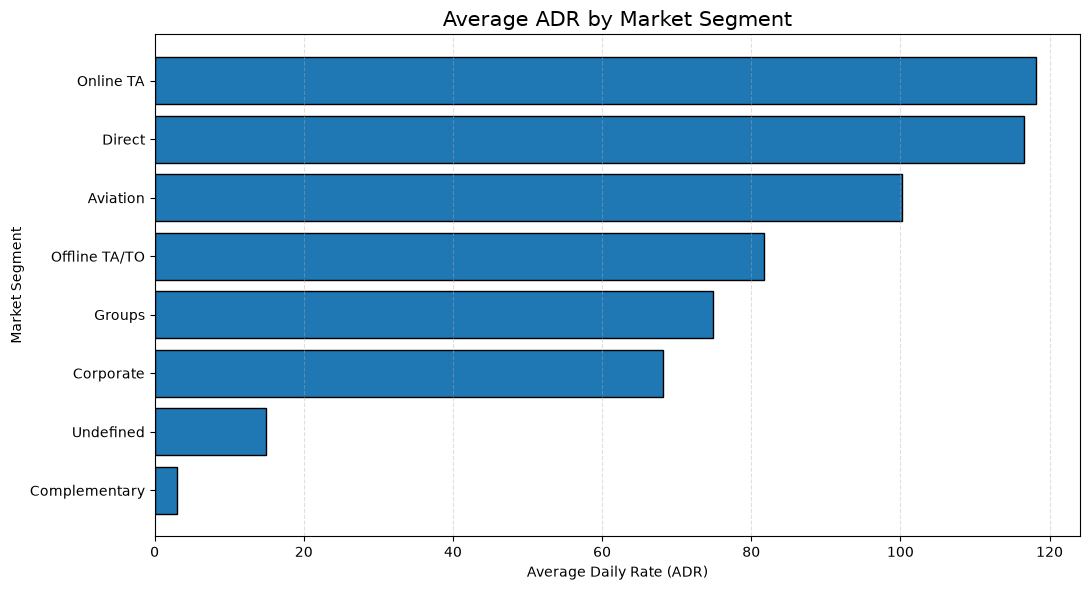

In [47]:
import matplotlib.pyplot as plt

adr_by_segment = (
    df.groupby('market_segment')['adr']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(11, 6))

plt.barh(
    adr_by_segment.index,
    adr_by_segment.values,
    edgecolor='black'
)

plt.title('Average ADR by Market Segment', fontsize=15)
plt.xlabel('Average Daily Rate (ADR)')
plt.ylabel('Market Segment')

plt.gca().invert_yaxis()
plt.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

Market segment analysis revealed that Online Travel Agents (Online TA) generated the highest average ADR of 118.17, closely followed by Direct bookings at 116.58. Corporate and Group bookings recorded comparatively lower average ADRs of 68.15 and 74.86, respectively. Complementary bookings had a particularly low average ADR of 3.05. These findings highlight differences in pricing patterns across booking channels and may help hotels develop segment-specific pricing and distribution strategies.

# Important: 
Undefined has only 2 bookings, while Aviation has 227. Interpret these averages cautiously because their sample sizes are relatively small.

# Bivariate analysis!

# Analysis 16 – Cancellation Rate by Market Segment
Which booking channels have the highest cancellation rates?

In [48]:
cancellation_by_segment = (
    df.groupby('market_segment')['is_canceled']
    .agg(['count', 'mean'])
)

cancellation_by_segment['cancellation_rate'] = (
    cancellation_by_segment['mean'] * 100
).round(2)

cancellation_by_segment = (
    cancellation_by_segment
    .drop(columns='mean')
    .sort_values('cancellation_rate', ascending=False)
)

print(cancellation_by_segment)

                count  cancellation_rate
market_segment                          
Undefined           2             100.00
Online TA       51618              35.35
Groups           4942              27.01
Aviation          227              19.82
Offline TA/TO   13889              14.85
Direct          11804              14.72
Complementary     702              12.54
Corporate        4212              12.11


# Analysis 17 – Cancellation Rate by Deposit Type
Do bookings with a Non-Refund deposit have lower cancellation rates than bookings with No Deposit?

In [49]:
cancellation_by_deposit = (
    df.groupby('deposit_type')['is_canceled']
    .agg(['count', 'mean'])
)

cancellation_by_deposit['cancellation_rate'] = (
    cancellation_by_deposit['mean'] * 100
).round(2)

print(
    cancellation_by_deposit
    .drop(columns='mean')
    .sort_values('cancellation_rate', ascending=False)
)

              count  cancellation_rate
deposit_type                          
Non Refund     1038              94.70
No Deposit    86251              26.68
Refundable      107              24.30


# Key findings:
- Non Refund bookings have an exceptionally high cancellation rate of 94.70%.
- No Deposit bookings account for the vast majority of bookings and have a 26.68% cancellation rate.
- Refundable bookings have a 24.30% cancellation rate, but the sample is relatively small.
An interesting finding: the Non Refund category has the highest cancellation rate, contrary to what we might intuitively expect. We should investigate this rather than assume the deposit policy caused the cancellations.
# Portfolio-ready insight
Deposit-type analysis revealed that Non Refund bookings recorded an exceptionally high cancellation rate of 94.70%, compared with 26.68% for No Deposit and 24.30% for Refundable bookings. This unexpected pattern highlights the importance of examining deposit policies and booking characteristics when investigating cancellation behaviour.

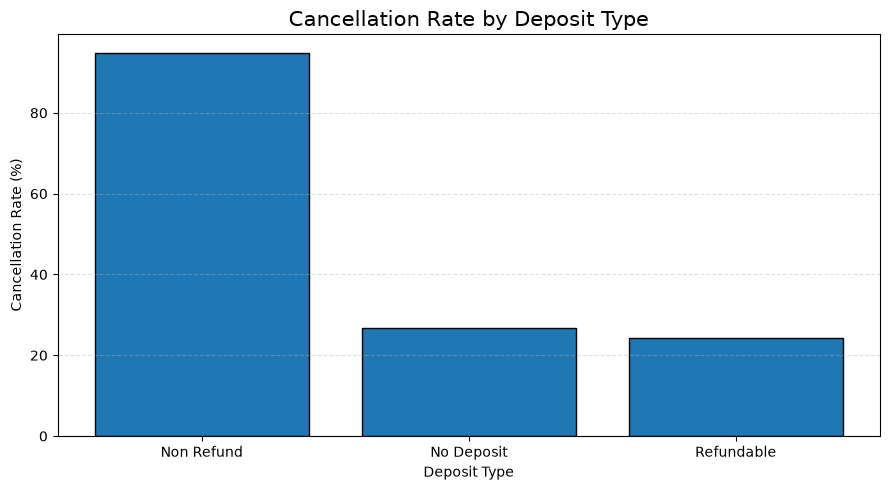

In [50]:
import matplotlib.pyplot as plt

cancellation_by_deposit = (
    df.groupby('deposit_type')['is_canceled']
    .mean() * 100
)

cancellation_by_deposit = cancellation_by_deposit.sort_values(
    ascending=False
)

plt.figure(figsize=(9, 5))

plt.bar(
    cancellation_by_deposit.index,
    cancellation_by_deposit.values,
    edgecolor='black'
)

plt.title('Cancellation Rate by Deposit Type', fontsize=15)
plt.xlabel('Deposit Type')
plt.ylabel('Cancellation Rate (%)')
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

# Analysis 18 – Cancellation Rate vs. Lead Time.
Business question
# Are customers who book further in advance more likely to cancel?

In [51]:
# Grouping bookings by lead time
df['lead_time_group'] = pd.cut(
    df['lead_time'],
    bins=[-1, 7, 30, 90, 180, 365, float('inf')],
    labels=[
        '0–7 Days',
        '8–30 Days',
        '31–90 Days',
        '91–180 Days',
        '181–365 Days',
        'Above 365 Days'
    ]
)

# Calculating cancellation rate
cancellation_by_lead_time = (
    df.groupby('lead_time_group', observed=False)['is_canceled']
    .agg(['count', 'mean'])
)

cancellation_by_lead_time['cancellation_rate'] = (
    cancellation_by_lead_time['mean'] * 100
).round(2)

print(
    cancellation_by_lead_time.drop(columns='mean')
)

                 count  cancellation_rate
lead_time_group                          
0–7 Days         18304               8.43
8–30 Days        16340              25.37
31–90 Days       22744              32.01
91–180 Days      18243              34.98
181–365 Days     11200              39.68
Above 365 Days     565              40.88


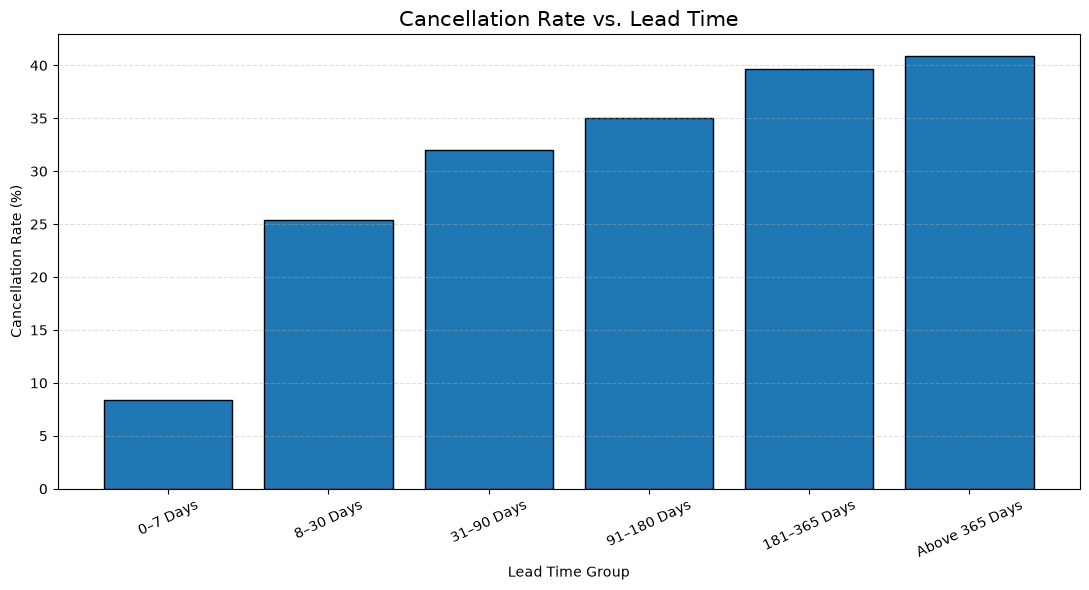

In [52]:
import matplotlib.pyplot as plt

cancellation_by_lead_time = (
    df.groupby('lead_time_group', observed=False)['is_canceled']
    .mean() * 100
)

plt.figure(figsize=(11, 6))

plt.bar(
    cancellation_by_lead_time.index.astype(str),
    cancellation_by_lead_time.values,
    edgecolor='black'
)

plt.title('Cancellation Rate vs. Lead Time', fontsize=15)
plt.xlabel('Lead Time Group')
plt.ylabel('Cancellation Rate (%)')

plt.xticks(rotation=25)
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

# Key findings
1. Bookings made within 7 days have the lowest cancellation rate (8.43%).
2. Cancellation rates increase consistently as lead time increases.
3. Bookings made 181–365 days in advance have a 39.68% cancellation rate.
4. The difference between the shortest and longest lead-time groups is 32.45 percentage points.
5. The Above 365 Days group has only 565 bookings, so interpret its rate cautiously.

# Portfolio-ready insight
Lead-time analysis revealed a clear positive association between booking lead time and cancellation rates. Bookings made within 7 days of arrival recorded the lowest cancellation rate of 8.43%, whereas bookings made 181–365 days in advance recorded a cancellation rate of 39.68%. This suggests that reservations made significantly earlier may carry greater cancellation risk. Hotels could consider targeted confirmation and engagement strategies for long-lead-time bookings.

# Important: 
This is an observed association, not proof that longer lead times cause cancellations.

# Analysis 19 – Cancellation Rate vs. Customer Type
Our final planned bivariate investigation! 🎯

In [53]:
cancellation_by_customer = (
    df.groupby('customer_type')['is_canceled']
    .agg(['count', 'mean'])
)

cancellation_by_customer['cancellation_rate'] = (
    cancellation_by_customer['mean'] * 100
).round(2)

print(
    cancellation_by_customer
    .drop(columns='mean')
    .sort_values('cancellation_rate', ascending=False)
)

                 count  cancellation_rate
customer_type                            
Transient        71986              30.11
Contract          3139              16.31
Transient-Party  11727              15.24
Group              544               9.93


# What this tells us:
- Transient customers have the highest cancellation rate at 30.11%.
- Group customers have the lowest rate at 9.93%, although the group sample is relatively small.
- Contract and Transient-Party bookings show relatively similar cancellation rates.
- Transient bookings also account for the largest number of records, so their cancellation behaviour is particularly important for hotel operations.
# Portfolio-ready insight
Customer-type analysis revealed that Transient bookings recorded the highest cancellation rate at 30.11%, while Group bookings had the lowest rate at 9.93%. Contract and Transient-Party bookings recorded cancellation rates of 16.31% and 15.24%, respectively. These findings indicate that cancellation behaviour varies considerably across customer categories, suggesting the value of customer-type-specific booking confirmation and retention strategies.

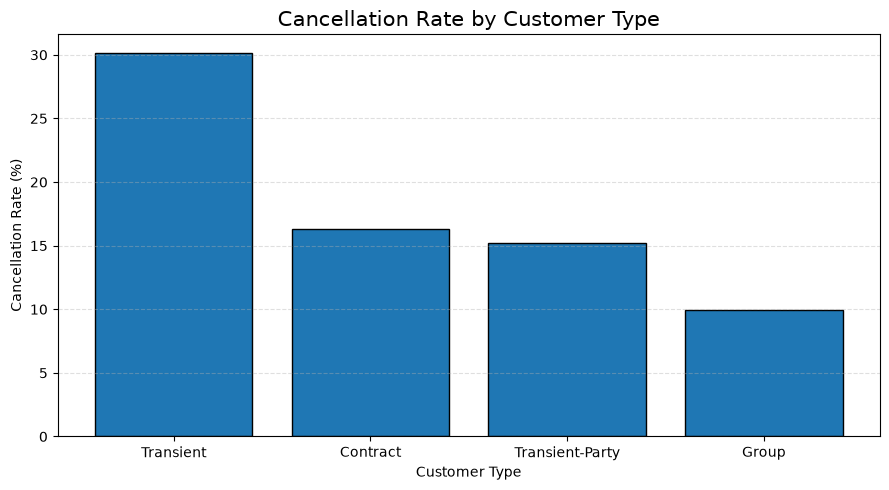

In [54]:
import matplotlib.pyplot as plt

cancellation_by_customer = (
    df.groupby('customer_type')['is_canceled']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

plt.bar(
    cancellation_by_customer.index,
    cancellation_by_customer.values,
    edgecolor='black'
)

plt.title('Cancellation Rate by Customer Type', fontsize=15)
plt.xlabel('Customer Type')
plt.ylabel('Cancellation Rate (%)')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# Multivariate Analysis

# Analysis 20 – Cancellation Rate by Hotel Type and Lead Time
# Business question: 
Does the relationship between booking lead time and cancellation rate differ between City Hotels and Resort Hotels?

In [55]:
# Calculating cancellation rates
cancellation_hotel_lead = df.pivot_table(
    index='lead_time_group',
    columns='hotel',
    values='is_canceled',
    aggfunc='mean',
    observed=False
) * 100

print(cancellation_hotel_lead.round(2))

hotel            City Hotel  Resort Hotel
lead_time_group                          
0–7 Days              10.50          5.99
8–30 Days             27.85         20.86
31–90 Days            33.11         29.80
91–180 Days           36.68         32.04
181–365 Days          44.48         34.38
Above 365 Days        51.33         20.11


In [56]:
# Calculating booking counts
booking_hotel_lead = df.pivot_table(
    index='lead_time_group',
    columns='hotel',
    values='is_canceled',
    aggfunc='count',
    observed=False
)

print(booking_hotel_lead)

hotel            City Hotel  Resort Hotel
lead_time_group                          
0–7 Days               9895          8409
8–30 Days             10530          5810
31–90 Days            15177          7567
91–180 Days           11573          6670
181–365 Days           5877          5323
Above 365 Days          376           189


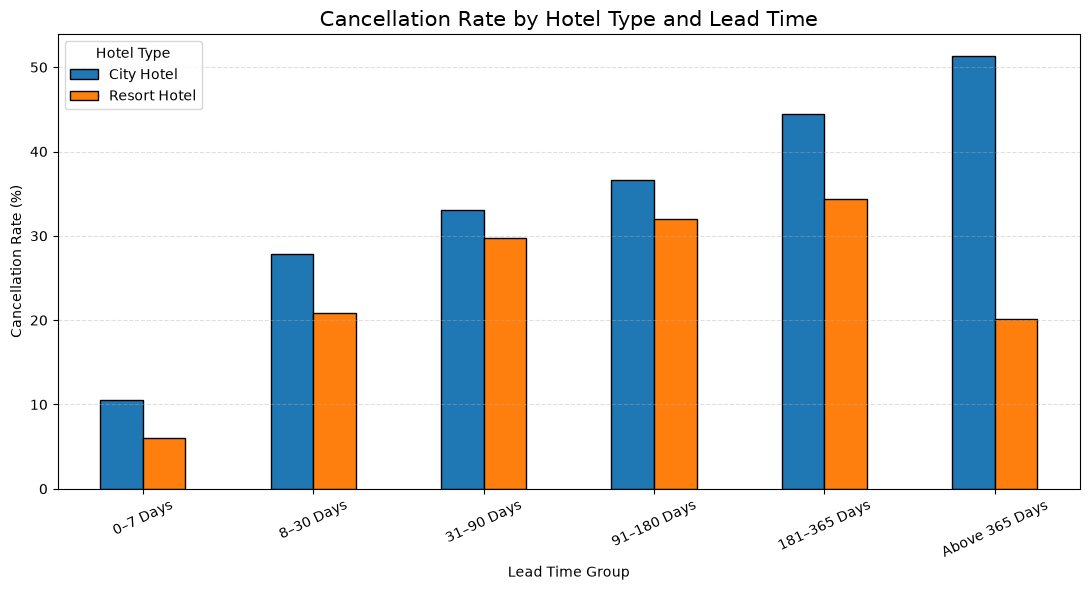

In [57]:
import matplotlib.pyplot as plt

cancellation_hotel_lead.plot(
    kind='bar',
    figsize=(11, 6),
    edgecolor='black'
)

plt.title(
    'Cancellation Rate by Hotel Type and Lead Time',
    fontsize=15
)
plt.xlabel('Lead Time Group')
plt.ylabel('Cancellation Rate (%)')
plt.xticks(rotation=25)
plt.legend(title='Hotel Type')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# 1. Key findings
City Hotels
- Cancellation rates increase consistently with lead time.
- 0–7 days: 10.50%
- 181–365 days: 44.48%
- Above 365 days: 51.33%
Resort Hotels
- Cancellation rates also generally increase with lead time.
- 0–7 days: 5.99%
- 181–365 days: 34.38%
- Above 365 days: 20.11%
# 2. Important observation
City Hotels have higher cancellation rates than Resort Hotels across every lead-time category.

The most interesting result is the Above 365 Days category:
- City Hotel: 51.33% (376 bookings)
- Resort Hotel: 20.11% (189 bookings)
However, both samples are relatively small compared with other categories, so interpret this difference cautiously.
# 3. Portfolio-ready insight
Multivariate analysis revealed that cancellation rates generally increased with booking lead time across both hotel types. City Hotels consistently recorded higher cancellation rates than Resort Hotels within every lead-time category. The highest cancellation rate was observed among City Hotel bookings made more than 365 days in advance (51.33%), compared with 20.11% for Resort Hotels. These findings suggest that cancellation management strategies should consider both hotel type and booking lead time.

# Analysis 21 – Cancellation Rate by Customer Type and Deposit Type
# Business question: Do cancellation patterns across customer types change depending on the deposit arrangement?

In [58]:
cancellation_customer_deposit = df.pivot_table(
    index='customer_type',
    columns='deposit_type',
    values='is_canceled',
    aggfunc='mean'
) * 100

print(cancellation_customer_deposit.round(2))

deposit_type     No Deposit  Non Refund  Refundable
customer_type                                      
Contract              15.50      100.00      100.00
Group                 10.02         NaN        0.00
Transient             29.25      100.00      100.00
Transient-Party       14.64       63.58        9.52


In [59]:
booking_customer_deposit = df.pivot_table(
    index='customer_type',
    columns='deposit_type',
    values='is_canceled',
    aggfunc='count'
)

print(booking_customer_deposit)

deposit_type     No Deposit  Non Refund  Refundable
customer_type                                      
Contract             3109.0        28.0         2.0
Group                 539.0         NaN         5.0
Transient           71111.0       859.0        16.0
Transient-Party     11492.0       151.0        84.0


# A. No Deposit
- Transient customers have the highest cancellation rate (29.25%).
- Group customers have the lowest (10.02%).
- This category has the largest sample sizes, making these comparisons more reliable.
# B. Non Refund
- Contract and Transient bookings show 100% cancellation.
- Transient-Party bookings show 63.58%.
- However, sample sizes are very small compared with No Deposit.
# C. Refundable
- Contract and Transient show 100%, but their sample sizes are only 2 and 16.
- Group bookings show 0% from just 5 records.
- Transient-Party has 9.52% from 84 records.
Important: These small samples should not be treated as reliable evidence of general customer behaviour. The 100% cancellation rates are observations in this dataset, not proof that the deposit arrangements caused cancellations.
# 3. Portfolio-ready insight
Multivariate analysis revealed that cancellation behaviour varied across combinations of customer type and deposit arrangement. Under the No Deposit category, Transient customers recorded the highest cancellation rate (29.25%), while Group customers recorded the lowest (10.02%). Several customer and deposit combinations showed extremely high cancellation rates, including 100% for certain categories. However, these combinations contained relatively few observations, requiring cautious interpretation. The findings highlight the importance of considering both customer characteristics and deposit arrangements when evaluating cancellation patterns.

# Analysis 22 – Average ADR by Hotel Type and Market Segment
# Business question: Does pricing vary across market segments differently for City Hotels and Resort Hotels?

In [60]:
adr_hotel_segment = df.pivot_table(
    index='market_segment',
    columns='hotel',
    values='adr',
    aggfunc='mean'
)

print(adr_hotel_segment.round(2))

hotel           City Hotel  Resort Hotel
market_segment                          
Aviation            100.17           NaN
Complementary         2.75          3.87
Corporate            82.69         51.84
Direct              120.85        112.78
Groups               84.75         63.58
Offline TA/TO        87.28         75.71
Online TA           119.78        114.78
Undefined            15.00           NaN


In [61]:
booking_hotel_segment = df.pivot_table(
    index='market_segment',
    columns='hotel',
    values='adr',
    aggfunc='count'
)

print(booking_hotel_segment)

hotel           City Hotel  Resort Hotel
market_segment                          
Aviation             227.0           NaN
Complementary        513.0         189.0
Corporate           2227.0        1985.0
Direct              5559.0        6245.0
Groups              2635.0        2307.0
Offline TA/TO       7271.0        6618.0
Online TA          34994.0       16624.0
Undefined              2.0           NaN


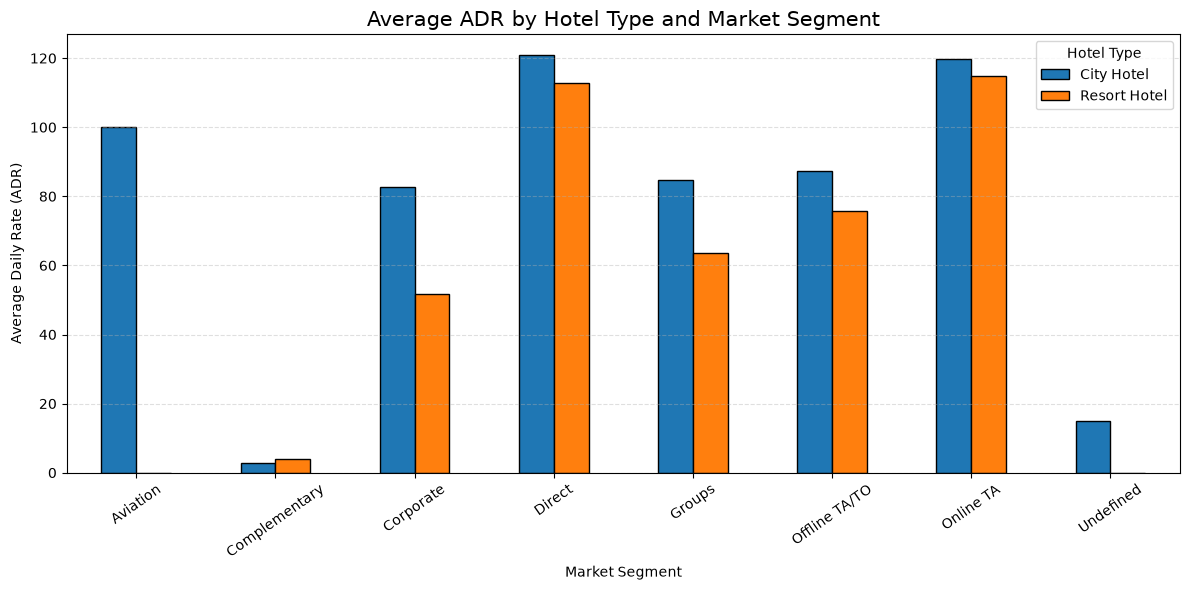

In [62]:
import matplotlib.pyplot as plt

adr_hotel_segment.plot(
    kind='bar',
    figsize=(12, 6),
    edgecolor='black'
)

plt.title(
    'Average ADR by Hotel Type and Market Segment',
    fontsize=15
)
plt.xlabel('Market Segment')
plt.ylabel('Average Daily Rate (ADR)')
plt.xticks(rotation=35)
plt.legend(title='Hotel Type')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# Important observations
# A. Online TA and Direct
- These are the highest-priced major booking segments for both hotel types.
- City Hotel Direct ADR: 120.85.
- Resort Hotel Online TA ADR: 114.78.
# B. Corporate and Groups
- Both segments show lower ADRs than Direct and Online TA.
- City Hotels record higher ADR than Resort Hotels in both segments.
# C. Complementary
- Very low ADR for both hotel types, consistent with complimentary or heavily discounted bookings.
# D. Sample-size awareness
- Aviation has only 227 City Hotel bookings.
- Undefined has only 2 bookings.
- Complementary has 702 bookings across both hotel types.
Avoid drawing strong conclusions from the smallest categories.
#  Portfolio-ready insight
Multivariate pricing analysis revealed differences in average daily rates across hotel types and market segments. Direct and Online TA bookings recorded the highest ADRs for both City and Resort Hotels, while Corporate and Group segments showed comparatively lower rates. City Hotels generally recorded higher ADRs than Resort Hotels within corresponding market segments. These findings suggest that pricing strategies should consider both hotel category and distribution channel when evaluating revenue opportunities.

# Analysis 23 – Chi-Square Test of Independence
# Business question
Is there a statistically significant association between hotel type and booking cancellation status?

We'll test:
- hotel – City Hotel / Resort Hotel
- is_canceled – 0 (Not Canceled) / 1 (Canceled)
# 1. Understand the hypotheses
- Null Hypothesis (H₀): Hotel type and cancellation status are independent. There is no statistically significant association.
- Alternative Hypothesis (H₁): Hotel type and cancellation status are associated.
We'll use a significance level of 0.05 (5%).

# 2. Running the Chi-Square test

In [63]:
from scipy.stats import chi2_contingency

# Create contingency table
contingency_table = pd.crosstab(
    df['hotel'],
    df['is_canceled']
)

print("Contingency Table:")
print(contingency_table)

# Perform Chi-Square test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("\nChi-Square Statistic:", chi2)
print("P-Value:", p_value)
print("Degrees of Freedom:", dof)

Contingency Table:
is_canceled       0      1
hotel                     
City Hotel    37379  16049
Resort Hotel  25992   7976

Chi-Square Statistic: 447.6635858339745
P-Value: 2.325877630100099e-99
Degrees of Freedom: 1


# Hypothesis decision
Our p-value is substantially smaller than 0.05.

Decision: Reject the Null Hypothesis (H₀).

There is a statistically significant association between hotel type and booking cancellation status.
# Business interpretation
- City Hotel cancellation rate: 30.04%
- Resort Hotel cancellation rate: 23.48%
- Difference: 6.56 percentage points
The statistical test confirms that the observed difference is unlikely to be explained by random sampling variation alone, under the null hypothesis.

This does not establish that hotel type causes cancellations.
# Portfolio-ready conclusion
A Chi-Square Test of Independence was conducted to examine the association between hotel type and booking cancellation status. The test produced a Chi-Square statistic of 447.66 with 1 degree of freedom and a p-value of 2.33 × 10⁻⁹⁹. Since the p-value was below the 0.05 significance level, the null hypothesis was rejected. The findings indicate a statistically significant association between hotel type and cancellation behaviour, with City Hotels recording a higher cancellation rate (30.04%) than Resort Hotels (23.48%).

# Analysis 24 – Correlation: Lead Time vs Cancellation
# Business question: Is booking lead time associated with cancellation behaviour?

We'll use the point-biserial correlation, which is appropriate for examining the relationship between:
- lead_time — continuous numerical variable.
- is_canceled — binary variable (0 or 1).
  # Interpretation guide
  | Correlation | General interpretation |
|---|---|
| Close to +1 | Strong positive relationship |
| Close to 0 | Weak or no linear relationship |
| Close to -1 | Strong negative relationship |



For this test:
- Positive correlation: longer lead times tend to be associated with cancellations.
- Negative correlation: longer lead times tend to be associated with non-cancellations.
- P-value ≤ 0.05: statistically significant association.

In [65]:
from scipy.stats import pointbiserialr

correlation, p_value = pointbiserialr(
    df['lead_time'],
    df['is_canceled']
)

print("Correlation:", correlation)
print("P-Value:", p_value)

Correlation: 0.18480558777334244
P-Value: 0.0


# Interpretation
Correlation = +0.1848
- Positive correlation means longer booking lead times tend to be associated with cancellations.
- However, 0.1848 indicates a weak positive relationship.
- Lead time alone is not a strong indicator of whether a booking will be canceled.
P-value = 0.0

This does not mean the true p-value is exactly zero. It means the value is too small for the computer's floating-point representation.

Since p-value < 0.05, the relationship is statistically significant.
# Business interpretation
Even though the relationship is statistically significant, its strength is weak.

This distinction matters: with a large dataset of 87,396 bookings, even relatively small relationships can become statistically significant.
# Portfolio-ready conclusion
A Point-Biserial Correlation analysis was conducted to examine the relationship between booking lead time and cancellation status. The test produced a correlation coefficient of 0.1848, indicating a weak positive association. The p-value was below the 0.05 significance level, demonstrating statistical significance. These findings suggest that longer booking lead times are associated with a greater likelihood of cancellation, although lead time alone has limited explanatory strength.

# Hotel Harmony – Business Insights & Recommendations

## 1. Key Business Insights

The exploratory and statistical analysis of 87,396 hotel booking records revealed several important patterns:

**1. Booking Cancellation Patterns**
- The overall cancellation rate was 27.49%.
- City Hotels recorded a higher cancellation rate (30.04%) than Resort Hotels (23.48%).
- Transient customers had the highest cancellation rate (30.11%), while Group customers had the lowest (9.93%).

**2. Lead-Time Impact**
- Bookings made further in advance generally showed higher cancellation rates.
- Reservations made within 7 days of arrival had an 8.43% cancellation rate.
- Reservations made 181–365 days in advance had a 39.68% cancellation rate.

**3. Customer and Deposit Behaviour**
- Cancellation patterns varied across customer types and deposit arrangements.
- Non Refund bookings showed an unexpectedly high cancellation rate of 94.70%.
- Some customer/deposit combinations had very small sample sizes and require further investigation.

**4. Seasonal Booking Trends**
- August recorded the highest booking volume (11,257), followed by July (10,057).
- January recorded the lowest booking volume (4,693).
- Booking volumes showed considerable seasonal variation.

**5. Pricing and Market Segments**
- City Hotels recorded a higher average ADR (110.99) than Resort Hotels (99.03).
- Online TA and Direct bookings recorded comparatively higher ADRs.
- Corporate and Group bookings showed lower average ADRs than these major channels.

**6. Guest and Stay Patterns**
- The average booking involved approximately two guests.
- The average stay duration was 3.63 nights.
- Resort Hotel bookings had longer average stays (4.39 nights) than City Hotel bookings (3.15 nights).

**7. Statistical Findings**
- The Chi-Square test identified a statistically significant association between hotel type and cancellation status.
- Point-Biserial Correlation identified a weak positive association between lead time and cancellation status (r = 0.1848).

---

## 2. Business Recommendations

### Recommendation 1: Strengthen Cancellation Management

City Hotels should receive particular attention because their cancellation rate is higher than that of Resort Hotels.

Hotels should:
- Monitor cancellation rates regularly.
- Introduce appropriate booking confirmation procedures.
- Identify customer categories with consistently higher cancellation rates.
- Develop targeted retention and engagement strategies.

### Recommendation 2: Monitor Long-Lead-Time Reservations

Bookings made significantly earlier have higher observed cancellation rates.

Hotels should:
- Send periodic booking confirmations.
- Introduce pre-arrival communication.
- Monitor long-lead-time reservations more closely.
- Consider appropriate reminder and reconfirmation processes.

### Recommendation 3: Develop Customer-Type-Specific Strategies

Transient customers represent the largest customer category and have the highest cancellation rate.

Hotels should:
- Monitor transient booking cancellations.
- Encourage booking confirmation and engagement.
- Develop suitable retention strategies.
- Maintain dedicated approaches for corporate and group customers.

### Recommendation 4: Review Deposit Policies

The exceptionally high cancellation rate among Non Refund bookings requires investigation.

Hotels should:
- Review deposit classification and booking conditions.
- Investigate why certain Non Refund reservations were canceled.
- Examine payment and booking workflows.
- Avoid changing deposit policies solely on the basis of cancellation percentages without investigating the underlying records.

### Recommendation 5: Improve Seasonal Resource Planning

Booking volumes peak during July and August.

Hotels should:
- Align staffing and operational resources with seasonal demand.
- Plan inventory and procurement ahead of peak periods.
- Review pricing strategies during high-demand months.
- Develop suitable promotional campaigns during relatively quieter months.

### Recommendation 6: Introduce Segment-Based Pricing Strategies

ADR varies considerably across market segments and hotel types.

Hotels should:
- Evaluate pricing separately for City and Resort Hotels.
- Monitor ADR performance across Direct, Online TA, Corporate and Group channels.
- Review the profitability of lower-ADR segments.
- Balance pricing competitiveness with revenue objectives.

### Recommendation 7: Optimize Stay-Based Services

Resort Hotel bookings have longer average stays than City Hotel bookings.

Hotels should:
- Develop packages suitable for longer stays.
- Consider extended-stay offers.
- Tailor services and operational planning to different stay durations.
- Evaluate weekday and weekend demand patterns separately.

### Recommendation 8: Improve Data Quality and Monitoring

The analysis identified unusual records, including zero-guest bookings, zero-night bookings, unusually high guest counts and extreme ADR values.

Hotels should:
- Introduce automated data validation.
- Investigate unusual booking records.
- Maintain consistent booking and customer information.
- Monitor missing values and duplicate records.
- Establish regular data-quality reporting procedures.

---

## 3. Final Business Conclusion

The Hotel Harmony project demonstrates how exploratory data analysis can transform raw hotel booking records into meaningful business insights.

The analysis identified important relationships involving hotel type, customer category, booking lead time, deposit arrangements, market segments, pricing and seasonal booking patterns.

Statistical testing further supported the presence of a significant association between hotel type and cancellation status, while correlation analysis identified a weak positive relationship between lead time and cancellation behaviour.

The findings suggest that hotels can improve operational planning, cancellation management and pricing decisions by adopting data-driven strategies.

Overall, this project demonstrates the practical application of Python, Pandas, NumPy, Matplotlib, Seaborn, exploratory data analysis and statistical methods to investigate real-world business problems and support informed decision-making.

**Project Title:** Hotel Harmony – Data Insights for Optimized Operations

**Project Type:** Exploratory Data Analysis (EDA) and Statistical Analysis

**Dataset:** Hotel Booking Demand

**Final Dataset:** 87,396 records and 34 columns, including derived analytical features.